In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import janitor

janitor

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 500)
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mapclassify import Quantiles

from utilities import add_segmented_scalebar, add_north_arrow, save_mpl_fig


FP_SUBZONE_SHP2014 = "input/master-plan-2014-subzone-boundary-no-sea/master-plan-2014-subzone-boundary-no-sea-shp.zip"
FP_CITYDATA_SUBZONES = "input/citydata-subzones.csv"
FP_HTYPE = "input/htype.csv"
FP_PRICE = "input/propprice-subzone.csv"
FP_MOVEMENT = "input/daily-movecount.csv.gz"
SAVEPATH = "../results/figures/supplementary/"

## Prep tables

### Shp

In [2]:
# Read in URA2014 version
subzones2014 = (
    gpd.read_file(FP_SUBZONE_SHP2014)
    .rename(columns={"SUBZONE_N": "subzone"})
    .assign(subzone=lambda df: df["subzone"].str.lower())
    .to_crs("EPSG:4326")
    .assign(centroid=lambda df: df["geometry"].centroid)
)

### Prices

In [3]:
df_price = (
    pd.read_csv(FP_PRICE)
    .rename_column("area", "subzone")
    .merge(
        (pd.read_csv(FP_HTYPE).rename_column("area", "subzone")),
        how="outer",
        on="subzone",
        validate="1:1",
    )
    .assign(
        wpsm_public=lambda df_: (100 - df_["private"]) / 100 * df_["public_psm"],
        wpsm_private=lambda df_: (df_["private"] / 100) * df_["private_psm"],
        wpsm=lambda df_: df_[["wpsm_public", "wpsm_private"]].sum(axis=1, skipna=True),
    )
    # 0 to nan
    .assign(
        wpsm=lambda x: x["wpsm"].replace(0, np.nan),
        resident_count=lambda x: x["resident_count"].replace(0, np.nan),
    )
    .assign(
        wpsm=lambda df_: df_["wpsm"].fillna(
            (
                (
                    df_["public_num_transactions"].fillna(0)
                    * df_["public_psm"].fillna(0)
                    + df_["private_num_transactions"].fillna(0) * df_["private_psm"]
                ).fillna(0)
                / (
                    df_["public_num_transactions"].fillna(0)
                    + df_["private_num_transactions"].fillna(0)
                )
            )
        )
    )
)
df_price

,subzone,num_transactions,psm,price,public_num_transactions,public_psm,public_price,private_num_transactions,private_psm,private_price,pa,htype,resident_count,private,rm12,rm3,rm4,rm5,wpsm_public,wpsm_private,wpsm
0,admiralty,374.0,3930.897154,3.698096e+05,374.0,3930.897154,369809.569519,NaN,NaN,NaN,Sembawang,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,14110.0,0.000000,8.079376,5.669738,42.168675,44.082211,3930.897154,NaN,3930.897154
1,airport road,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Paya Lebar,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,alexandra hill,184.0,5493.879995,5.314567e+05,184.0,5493.879995,531456.739130,NaN,NaN,NaN,Bukit Merah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,13350.0,0.000000,29.288390,18.876404,28.464419,23.370787,5493.879995,NaN,5493.879995
3,alexandra north,733.0,18564.409277,1.697418e+06,NaN,NaN,NaN,733.0,18564.409277,1.697418e+06,Bukit Merah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,2120.0,100.000000,0.000000,0.000000,0.000000,0.000000,NaN,18564.409277,18564.409277
4,aljunied,2311.0,12530.475712,1.034765e+06,442.0,5721.385452,537196.816742,1869.0,14140.758159,1.152435e+06,Geylang,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,38930.0,31.826355,5.445672,23.041356,23.246853,16.439764,3900.477008,4500.487891,8400.964898
5,anak bukit,909.0,13255.160067,1.720123e+06,129.0,6492.825591,793311.100775,780.0,14373.546154,1.873403e+06,Bukit Timah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,22040.0,75.408348,0.725953,0.045372,9.437387,14.382940,1596.693045,10838.853769,12435.546814
6,anchorvale,1702.0,7032.024787,7.018869e+05,917.0,4306.121252,448699.376227,785.0,10216.296815,9.976486e+05,Sengkang,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,46610.0,10.727312,3.604377,2.853465,34.220124,48.594722,3844.190202,1095.934007,4940.124209
7,ang mo kio town centre,170.0,10097.445115,1.045314e+06,63.0,6031.820152,629532.952381,107.0,12491.224299,1.290120e+06,Ang Mo Kio,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,4880.0,39.549180,0.000000,9.631148,13.319672,37.500000,3646.284723,4940.176823,8586.461546
8,anson,31.0,20121.516129,1.192871e+06,NaN,NaN,NaN,31.0,20121.516129,1.192871e+06,Downtown Core,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20121.516129
9,balestier,1419.0,11618.781112,1.134014e+06,444.0,4749.487384,433557.770270,975.0,14746.951795,1.452991e+06,Novena,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,32120.0,31.693649,5.572852,24.190535,24.034869,14.508095,3244.201532,4673.847113,7918.048645


In [4]:
(
    df_price.query("resident_count!=resident_count").query(
        "public_psm==public_psm | private_psm==private_psm"
    )
    #     .query("wpsm!=wpsm")
)

,subzone,num_transactions,psm,price,public_num_transactions,public_psm,public_price,private_num_transactions,private_psm,private_price,pa,htype,resident_count,private,rm12,rm3,rm4,rm5,wpsm_public,wpsm_private,wpsm
8,anson,31.0,20121.516129,1.192871e+06,NaN,NaN,NaN,31.0,20121.516129,1.192871e+06,Downtown Core,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20121.516129
19,bidadari,171.0,20202.403509,1.328374e+06,NaN,NaN,NaN,171.0,20202.403509,1.328374e+06,Toa Payoh,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20202.403509
52,city hall,134.0,32844.539734,4.829954e+06,8.0,5134.290541,352750.000000,126.0,34603.920635,5.114221e+06,Downtown Core,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32844.539734
103,istana negara,5.0,17580.000000,1.234700e+06,NaN,NaN,NaN,5.0,17580.000000,1.234700e+06,Newton,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17580.000000
116,kampong glam,3.0,6580.086580,5.066667e+05,3.0,6580.086580,506666.666667,NaN,NaN,NaN,Rochor,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
125,kent ridge,6.0,9136.166667,1.112167e+06,NaN,NaN,NaN,6.0,9136.166667,1.112167e+06,Queenstown,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136.166667


In [5]:
gdf_price = subzones2014[["subzone", "geometry", "PLN_AREA_N", "REGION_C"]].merge(
    df_price, how="right", on="subzone", validate="1:1"
)

gdf_sz_cr = gdf_price[gdf_price["REGION_C"] == "CR"]
gdf_sz_cr

,subzone,geometry,PLN_AREA_N,REGION_C,num_transactions,psm,price,public_num_transactions,public_psm,public_price,private_num_transactions,private_psm,private_price,pa,htype,resident_count,private,rm12,rm3,rm4,rm5,wpsm_public,wpsm_private,wpsm
2,alexandra hill,"POLYGON ((103.81445 1.28547, 103.81433 1.28501...",BUKIT MERAH,CR,184.0,5493.879995,5.314567e+05,184.0,5493.879995,531456.739130,NaN,NaN,NaN,Bukit Merah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,13350.0,0.000000,29.288390,18.876404,28.464419,23.370787,5493.879995,NaN,5493.879995
3,alexandra north,"POLYGON ((103.81743 1.29431, 103.81787 1.29393...",BUKIT MERAH,CR,733.0,18564.409277,1.697418e+06,NaN,NaN,NaN,733.0,18564.409277,1.697418e+06,Bukit Merah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,2120.0,100.000000,0.000000,0.000000,0.000000,0.000000,NaN,18564.409277,18564.409277
4,aljunied,"POLYGON ((103.89127 1.32132, 103.89153 1.32014...",GEYLANG,CR,2311.0,12530.475712,1.034765e+06,442.0,5721.385452,537196.816742,1869.0,14140.758159,1.152435e+06,Geylang,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,38930.0,31.826355,5.445672,23.041356,23.246853,16.439764,3900.477008,4500.487891,8400.964898
5,anak bukit,"POLYGON ((103.77104 1.34791, 103.77188 1.3466,...",BUKIT TIMAH,CR,909.0,13255.160067,1.720123e+06,129.0,6492.825591,793311.100775,780.0,14373.546154,1.873403e+06,Bukit Timah,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,22040.0,75.408348,0.725953,0.045372,9.437387,14.382940,1596.693045,10838.853769,12435.546814
8,anson,"POLYGON ((103.84411 1.27487, 103.84405 1.27448...",DOWNTOWN CORE,CR,31.0,20121.516129,1.192871e+06,NaN,NaN,NaN,31.0,20121.516129,1.192871e+06,Downtown Core,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20121.516129
9,balestier,"POLYGON ((103.86233 1.32956, 103.86218 1.32863...",NOVENA,CR,1419.0,11618.781112,1.134014e+06,444.0,4749.487384,433557.770270,975.0,14746.951795,1.452991e+06,Novena,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,32120.0,31.693649,5.572852,24.190535,24.034869,14.508095,3244.201532,4673.847113,7918.048645
11,bayfront subzone,"POLYGON ((103.85888 1.27874, 103.85843 1.27804...",DOWNTOWN CORE,CR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Downtown Core,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,bencoolen,"POLYGON ((103.85345 1.30262, 103.85345 1.30262...",ROCHOR,CR,68.0,10244.027864,8.346895e+05,31.0,6265.899830,349189.935484,37.0,13577.054054,1.241459e+06,Rochor,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,1190.0,23.529412,0.840336,68.067227,7.563025,0.000000,4791.570458,3194.600954,7986.171412
17,bendemeer,"POLYGON ((103.86277 1.3303, 103.86302 1.3302, ...",KALLANG,CR,1136.0,9613.051591,7.989783e+05,648.0,6057.215444,557831.217593,488.0,14334.735656,1.119190e+06,Kallang,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,36380.0,15.365585,5.250137,25.178670,38.290269,15.915338,5126.488827,2202.616061,7329.104888
19,bidadari,"POLYGON ((103.87859 1.34347, 103.87944 1.34299...",TOA PAYOH,CR,171.0,20202.403509,1.328374e+06,NaN,NaN,NaN,171.0,20202.403509,1.328374e+06,Toa Payoh,HDB 1- and 2-Room FlatsHDB 3-Room FlatsHDB 4-R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20202.403509


In [6]:
# Drop zones/subzones to shrink map
# https://www.citypopulation.de/en/singapore/admin/

subzones_to_drop = [
    "north-eastern islands",
    "sudong",
    "semakau",
    "jurong island and bukom",
    "southern group",
    "tuas bay",
    "tuas north",
    "tuas view",
    "tuas view extension",
    "tuas promenade",
    "changi airport",
    "changi bay",
    "tengeh",
    "western water catchment",
    "lim chu kang",
    "reservoir view",
    "gul circle",
    "pioneer sector",
    "safti",
    "joo koon",
    "gul basin",
    "benoi sector",
    "samulun",
    "senoko north",
    "the wharves",
    "kranji",
    "pang sua",
    "tanjong irau",
    "pulau seletar",
]
gdf_sz_cr = gdf_sz_cr[~gdf_sz_cr["subzone"].isin(subzones_to_drop)]

# zones_to_drop = ['SOUTHERN ISLANDS', 'NORTH-EASTERN ISLANDS', 'WESTERN ISLANDS']
# zones2014 = zones2014[~zones2014['PLN_AREA_N'].isin(zones_to_drop)]

### Flows

In [7]:
# Clean obvious name errors from Citydata (to get perfect match)
clean_cd_subzone = {
    "marina east mp": "marina east (mp)",
    "monks hill": "monk's hill",
    "national university of s pore": "national university of s'pore",
    "peoples park": "people's park",
}

In [8]:
# Read in citydata subzones
cd_subzones = (
    pd.read_csv(FP_CITYDATA_SUBZONES)
    .assign(subzone=lambda df: df["subzone"].str.lower())
    .assign(subzone=lambda df: df["subzone"].replace(clean_cd_subzone))
)

# Merge with URA shp
cd_subzones = cd_subzones.merge(
    subzones2014[["subzone", "geometry"]], how="left", on="subzone", indicator=True
)

assert len(cd_subzones[cd_subzones["_merge"] == "left_only"]) == 0

subzones_dict = dict(zip(cd_subzones["areaid"], cd_subzones["subzone"]))

cd_subzones.head(3)

,subzone,areaid,geometry,_merge
0,admiralty,0,"POLYGON ((103.82855 1.45878, 103.82871 1.45854...",both
1,airport road,1,"POLYGON ((103.90143 1.35617, 103.9012 1.35572,...",both
2,alexandra hill,2,"POLYGON ((103.81445 1.28547, 103.81433 1.28501...",both


In [9]:
# Read in movement matrix for weekdays and map area xid back to citydata subzone name
move = (
    pd.read_csv(FP_MOVEMENT, compression="gzip")
    .assign(date=lambda df: pd.to_datetime(df["date"]))
    #         .assign(dow=lambda df: [ts.isoweekday() for ts in df['date']])
    #         .query('dow<6')
    #         #         .drop('date', axis=1)
    .groupby(["home", "area_id"])["inflow_count"]
    .sum()
    .reset_index()
    .assign(source=lambda df: df["home"].map(subzones_dict))
    .assign(dest=lambda df: df["area_id"].map(subzones_dict))
    .assign(source=lambda df: df["source"].str.lower())
    .assign(dest=lambda df: df["dest"].str.lower())
    .assign(source=lambda df: df["source"].replace(clean_cd_subzone))
    .assign(dest=lambda df: df["dest"].replace(clean_cd_subzone))
)

# Merge with URA shp
move = (
    move.merge(
        subzones2014[["subzone", "centroid"]],
        how="left",
        left_on="source",
        right_on="subzone",
    )
    .assign(slong=lambda df: [pt.coords[0][0] for pt in df["centroid"]])
    .assign(slat=lambda df: [pt.coords[0][1] for pt in df["centroid"]])
    .drop("centroid", axis=1)
)

move = (
    move.merge(
        subzones2014[["subzone", "centroid"]],
        how="left",
        left_on="dest",
        right_on="subzone",
    )
    .assign(dlong=lambda df: [pt.coords[0][0] for pt in df["centroid"]])
    .assign(dlat=lambda df: [pt.coords[0][1] for pt in df["centroid"]])
)

# Get total home for percentages
move = move.merge(
    move.groupby(["home"])["inflow_count"]
    .sum()
    .reset_index()
    .rename(columns={"inflow_count": "tt"}),
    how="left",
    on=["home"],
    validate="m:1",
)
move["flow"] = move["inflow_count"] / move["tt"] * 100

move.drop(
    ["subzone_x", "subzone_y", "centroid", "home", "area_id"], axis=1, inplace=True
)

move.head(3)

,inflow_count,source,dest,slong,slat,dlong,dlat,tt,flow
0,813,admiralty,admiralty,103.825153,1.453388,103.825153,1.453388,2890,28.131488
1,1,admiralty,airport road,103.825153,1.453388,103.897416,1.351570,2890,0.034602
2,1,admiralty,alexandra hill,103.825153,1.453388,103.809587,1.287506,2890,0.034602


## Plot

### Preamble

In [13]:
# Graph settings
FIGSIZE = (10, 10)

AREA_LINEWIDTH = 1.5
EDGE_COLOR = "darkgray"

ZONE_LINEWIDTH = 3
ZONE_EDGECOLOR = "dimgray"

MOVE_COLOR = "black"
MOVE_LINE_ALPHA = 0.99
MOVE_LWIDTH_NORM = 100  # smaller = thicker

FLOW_CUTOFF = 1  # at least 1 percent flow

CM = "Oranges_r"
MISSKWDS = {
    "color": "black",
    "edgecolor": "white",
    "hatch": "///",
    "label": "Missing values",
}
SCALEBAR_OPTS = dict(
    height_fraction=.010,
    location="lower left",
    segments=[1, 1, 2, 2],
    unit_position="right",
    label_offset=0.005,
    unit_label_spacing=0.003,
    fontsize=10,
    unit_fontsize=11,
)

### mount pleasant

In [1]:
# # Plot mount pleasant
# SELECTED_AREA = "mount pleasant"
# _, ax = plt.subplots(figsize=FIGSIZE)
# # =====================================================
# # Plot wpsm
# gdf_sz_cr.plot(
#     column="wpsm",
#     cmap="Oranges",
#     scheme="quantiles",
#     edgecolor=EDGE_COLOR,
#     linewidth=AREA_LINEWIDTH,
#     ax=ax,
#     zorder=2,
# )
# # =====================================================
# # Plot non-resid hatching
# gdf_sz_cr.query("resident_count!=resident_count").query("wpsm!=wpsm").plot(
#     column="resident_count",
#     alpha=0.5,
#     edgecolor=EDGE_COLOR,
#     missing_kwds=MISSKWDS,
#     ax=ax,
#     zorder=1,
# )

# # =====================================================
# # Highlight selected area border
# selected_gdf = gdf_sz_cr[gdf_sz_cr["subzone"] == SELECTED_AREA]
# selected_gdf.boundary.plot(ax=ax, color="#000080", linewidth=7, zorder=5, alpha=0.7)

# selected_gdf = gdf_sz_cr[gdf_sz_cr["subzone"] == "toa payoh central"]
# selected_gdf.boundary.plot(ax=ax, color="#008080", linewidth=6, zorder=5, alpha=0.7)

# # =====================================================
# # Plot movement lines
# for slat, dlat, slon, dlon, area, flow, base in zip(
#     move["slat"],
#     move["dlat"],
#     move["slong"],
#     move["dlong"],
#     move["source"],
#     move["flow"],
#     move["inflow_count"],
# ):
#     if area == SELECTED_AREA:
#         #         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
#         if flow > FLOW_CUTOFF:
#             plt.plot(
#                 [slon, dlon],
#                 [slat, dlat],
#                 linewidth=base / MOVE_LWIDTH_NORM,
#                 color="#000080",
#                 alpha=MOVE_LINE_ALPHA,
#                 zorder=4,
#                 linestyle=":",
#                 marker=">",
#             )

# # =====================================================
# # Get quantiles
# classifier = Quantiles(gdf_sz_cr["wpsm"], k=5)
# breaks = classifier.bins
# colors = [plt.cm.Oranges(i / 4) for i in range(5)]


# def format_price(price):
#     if price >= 1000:
#         return f"{price/1000:.1f}k"
#     else:
#         return f"{price:.0f}"


# # =====================================================
# # Compose legend
# legend_elements = []

# # Add quantile legend items
# for i, (color, break_val) in enumerate(zip(colors, breaks)):
#     if i == 0:
#         label = f"< \${format_price(break_val)}"
#     elif i == 4:
#         label = f"> \${format_price(breaks[i-1])}"
#     else:
#         label = f"\${format_price(breaks[i-1])} - \${format_price(break_val)}"
#     legend_elements.append(
#         mpatches.Patch(facecolor=color, edgecolor="black", linewidth=0.5, label=label)
#     )

# # Add non-residential areas to legend
# legend_elements.append(
#     mpatches.Patch(
#         facecolor=MISSKWDS.get("color", "lightgray"),
#         hatch=MISSKWDS.get("hatch", "/////"),
#         alpha=0.5,
#         edgecolor=MISSKWDS.get("facecolor", "lightgray"),
#         linewidth=0.5,
#         label="Non-residential",
#     )
# )

# legend = ax.legend(
#     handles=legend_elements,
#     title="Weighted price per\nsqm (SGD)",
#     title_fontsize=15,
#     fontsize=15,
#     loc="lower right",
#     bbox_to_anchor=(1.0, 0),
#     frameon=False,
#     shadow=False,
#     framealpha=0.95,
#     edgecolor="#333333",
#     facecolor="white",
#     borderpad=0,
#     columnspacing=1,
#     labelspacing=0.4,
#     handletextpad=0.5,
# )
# legend.get_title().set_fontweight("bold")
# legend._legend_box.align = "left"
# for text in legend.get_texts():
#     text.set_color(".2")
# # =====================================================
# # add_scalebar(ax=ax, location="upper right")
# add_north_arrow(ax=ax, x=103.915, y=1.36)
# add_segmented_scalebar(
#     ax,
#     location="lower left",
#     segments=[1, 1, 2, 2],
#     unit_position="right",
#     label_offset=0.005,
#     unit_label_spacing=0.003,
#     fontsize=10,
#     unit_fontsize=11,
# )
# plt.tight_layout()
# plt.margins(0, 0)
# plt.axis("off")
# save_mpl_fig(f"{SAVEPATH}/outflow-{'_'.join(SELECTED_AREA.split(' '))}-wpsm")

### Malcolm

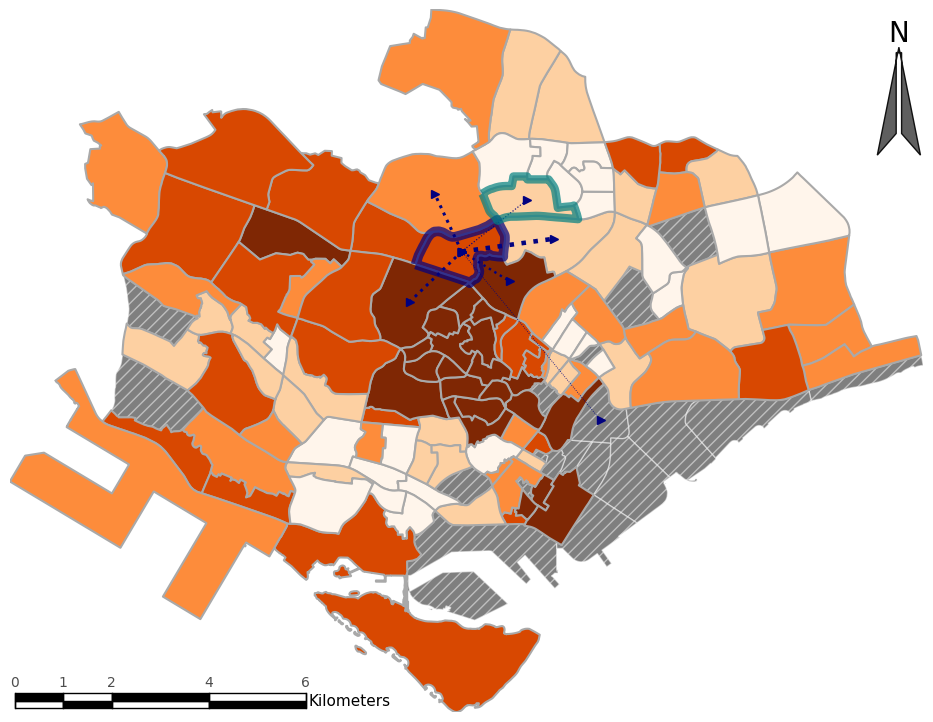

In [15]:
# Plot mount pleasant
SELECTED_AREA = "malcolm"
_, ax = plt.subplots(figsize=FIGSIZE)
# =====================================================
# Plot wpsm
gdf_sz_cr.plot(
    column="wpsm",
    cmap="Oranges",
    scheme="quantiles",
    edgecolor=EDGE_COLOR,
    linewidth=AREA_LINEWIDTH,
    ax=ax,
    zorder=2,
)
# =====================================================
# Plot non-resid hatching
gdf_sz_cr.query("resident_count!=resident_count").query("wpsm!=wpsm").plot(
    column="resident_count",
    alpha=0.5,
    edgecolor=EDGE_COLOR,
    missing_kwds=MISSKWDS,
    ax=ax,
    zorder=1,
)

# =====================================================
# Highlight selected area border
selected_gdf = gdf_sz_cr[gdf_sz_cr["subzone"] == SELECTED_AREA]
selected_gdf.boundary.plot(ax=ax, color="#000080", linewidth=7, zorder=5, alpha=0.7)

selected_gdf = gdf_sz_cr[gdf_sz_cr["subzone"] == "toa payoh central"]
selected_gdf.boundary.plot(ax=ax, color="#008080", linewidth=6, zorder=5, alpha=0.7)

# =====================================================
# Plot movement lines
for slat, dlat, slon, dlon, area, flow, base in zip(
    move["slat"],
    move["dlat"],
    move["slong"],
    move["dlong"],
    move["source"],
    move["flow"],
    move["inflow_count"],
):
    if area == SELECTED_AREA:
        #         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow > FLOW_CUTOFF:
            plt.plot(
                [slon, dlon],
                [slat, dlat],
                linewidth=base / MOVE_LWIDTH_NORM,
                color="#000080",
                alpha=MOVE_LINE_ALPHA,
                zorder=4,
                linestyle=":",
                marker=">",
            )

# =====================================================
# add_scalebar(ax=ax, location="upper right")
add_north_arrow(ax=ax, x=103.915, y=1.36)
add_segmented_scalebar(
    ax,
    **SCALEBAR_OPTS,
)
plt.tight_layout()
plt.margins(0, 0)
plt.axis("off")
save_mpl_fig(f"{SAVEPATH}/outflow-{'_'.join(SELECTED_AREA.split(' '))}-wpsm")

### toa payoh central

In [18]:
import matplotlib

In [19]:
matplotlib.__version__

'3.7.5'

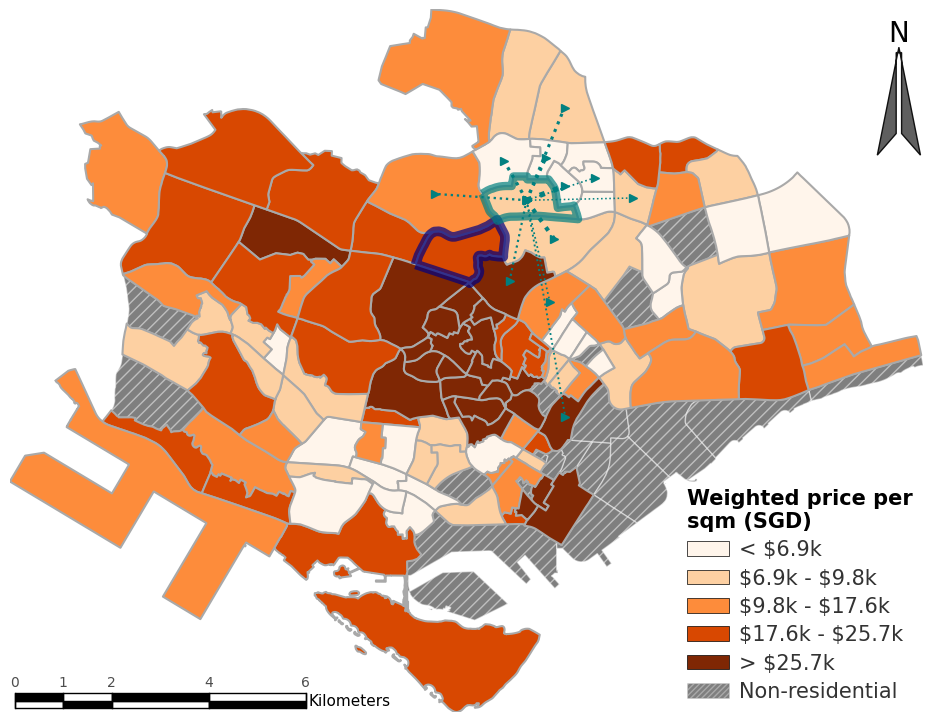

In [26]:
# Plot toa payoh central
SELECTED_AREA = "toa payoh central"

_, ax = plt.subplots(figsize=FIGSIZE)

# =====================================================
# Plot wpsm
gdf_sz_cr.plot(
    column="wpsm",
    cmap="Oranges",
    scheme="quantiles",
    edgecolor=EDGE_COLOR,
    linewidth=AREA_LINEWIDTH,
    ax=ax,
    zorder=2,
)

# =====================================================
# Plot non-resid
gdf_sz_cr.query("resident_count!=resident_count").query("wpsm!=wpsm").plot(
    column="resident_count",
    alpha=0.5,
    edgecolor=EDGE_COLOR,
    missing_kwds=MISSKWDS,
    ax=ax,
    zorder=1,
)

# =====================================================
# Highlight selected area border
selected_gdf = gdf_sz_cr[gdf_sz_cr["subzone"] == "malcolm"]
selected_gdf.boundary.plot(ax=ax, color="#000080", linewidth=7, zorder=5, alpha=0.7)

selected_gdf = gdf_sz_cr[gdf_sz_cr["subzone"] == SELECTED_AREA]
selected_gdf.boundary.plot(ax=ax, color="#008080", linewidth=6, zorder=5, alpha=0.7)

# =====================================================
# Plot movement lines
for slat, dlat, slon, dlon, area, flow, base in zip(
    move["slat"],
    move["dlat"],
    move["slong"],
    move["dlong"],
    move["source"],
    move["flow"],
    move["inflow_count"],
):
    if area == SELECTED_AREA:
        #         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow > FLOW_CUTOFF:
            plt.plot(
                [slon, dlon],
                [slat, dlat],
                linewidth=base / (MOVE_LWIDTH_NORM * 5),
                color="#008080",
                alpha=MOVE_LINE_ALPHA,
                zorder=4,
                linestyle=":",
                marker=">",
            )

# =====================================================
# Get quantiles
classifier = Quantiles(gdf_sz_cr["wpsm"], k=5)
breaks = classifier.bins
colors = [plt.cm.Oranges(i / 4) for i in range(5)]


def format_price(price):
    if price >= 1000:
        return f"{price/1000:.1f}k"
    else:
        return f"{price:.0f}"


# =====================================================
# Compose legend
legend_elements = []

# Add quantile legend items
for i, (color, break_val) in enumerate(zip(colors, breaks)):
    if i == 0:
        label = f"< \${format_price(break_val)}"
    elif i == 4:
        label = f"> \${format_price(breaks[i-1])}"
    else:
        label = f"\${format_price(breaks[i-1])} - \${format_price(break_val)}"
    legend_elements.append(
        mpatches.Patch(facecolor=color, edgecolor="black", linewidth=0.5, label=label)
    )

# Add non-residential areas to legend
legend_elements.append(
    mpatches.Patch(
        facecolor=MISSKWDS.get("color", "lightgray"),
        hatch="//////",
        alpha=0.5,
        edgecolor=MISSKWDS.get("facecolor", "lightgray"),
        linewidth=0.5,
        label="Non-residential",
    )
)

legend = ax.legend(
    handles=legend_elements,
    title="Weighted price per\nsqm (SGD)",
    title_fontsize=15,
    fontsize=15,
    loc="lower right",
    bbox_to_anchor=(1.0, 0),
    frameon=False,
    shadow=False,
    framealpha=0.95,
    edgecolor="#333333",
    facecolor="white",
    borderpad=0,
    columnspacing=1,
    labelspacing=0.4,
    handletextpad=0.5,
)
legend.get_title().set_fontweight("bold")
legend._legend_box.align = "left"
for text in legend.get_texts():
    text.set_color(".2")
    
# =====================================================
# add_scalebar(ax=ax, location="upper right")
add_north_arrow(ax=ax, x=103.915, y=1.36)
add_segmented_scalebar(
    ax,
    **SCALEBAR_OPTS,
)
plt.tight_layout()
plt.margins(0, 0)
plt.axis("off")
save_mpl_fig(f"{SAVEPATH}/outflow-{'_'.join(SELECTED_AREA.split(' '))}-wpsm")